<a href="https://colab.research.google.com/github/sjlee53/ESAA-submission/blob/YB/YB_1120_%EC%97%B0%EC%8A%B5%EB%AC%B8%EC%A0%9C_%ED%9A%8C%EA%B7%802.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [4]:
# 데이터 로드
data = pd.read_csv("abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [5]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [6]:
# train과 test set 분리 (train:test = 7:3 비율로)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [7]:
#필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [10]:
#릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3)
ridge.fit(X_train, y_train)

#예측값 구하기
pred = ridge.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
age_pred = pred + 1.5
age_true = y_test + 1.5

#MSE와 RMSE구하기
mse = mean_squared_error(age_true, age_pred)
rmse = np.sqrt(mse)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse, rmse))

MSE: 4.772, RMSE: 2.185


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [11]:
data.columns
pd.Series(ridge.coef_, index=data.columns).sort_values(ascending=False)

,0
Shell weight,9.360811
Height,8.886406
Whole weight,8.625577
Diameter,7.950942
Length,2.286643
M,0.309268
F,0.223771
I,-0.533039
Viscera weight,-8.644888
Shucked weight,-20.040631


껍질무게(+9.36)·높이(+8.89)·전체무게(+8.63)·지름(+7.95)은 값이 클수록 고리수가 늘고, 몸통무게(−20.04)와 내장무게(−8.65)는 반대로 줄인다. 전체무게는 양수인데 몸통무게가 큰 음수인 점이 핵심인데, 같은 전체무게라면 살이 적고 껍질이 무거운 쪽이 나이가 많다는 뜻이다. 전복이 자라면서 살보다 껍질이 두꺼워지는 특성이 계수로 드러난 것이다. 성별(M·F·I)의 계수는 ±0.5 이내로 작아 영향이 거의 없고, 그중 Infant(−0.53)만 음수인 것은 어린 개체라는 사실과 맞는다

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [13]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [14]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함
#cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산
for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    neg_mse_scores = cross_val_score(ridge, X, y, scoring="neg_mean_squared_error", cv=5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print('alpha {0} 일 때 5 folds 의 평균 RMSE : {1:.3f}'.format(alpha, avg_rmse))

alpha 0 일 때 5 folds 의 평균 RMSE : 2.245
alpha 0.1 일 때 5 folds 의 평균 RMSE : 2.237
alpha 1 일 때 5 folds 의 평균 RMSE : 2.230
alpha 10 일 때 5 folds 의 평균 RMSE : 2.337
alpha 100 일 때 5 folds 의 평균 RMSE : 2.621


## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [15]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [17]:
#모델 생성 및 훈련
xgb = XGBRegressor(random_state=42)
xgb.fit(X_train, y_train)

#예측값 구하기
xgb_pred = xgb.predict(X_test)

#구한 예측값을 활용해 최종적으로 전복의 나이 예측
xgb_age_pred = xgb_pred + 1.5

#MSE와 RMSE 구하기
mse = mean_squared_error(y_test + 1.5, xgb_age_pred)
rmse = np.sqrt(mse)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse, rmse))

MSE: 5.383, RMSE: 2.320


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

<Axes: ylabel='None'>

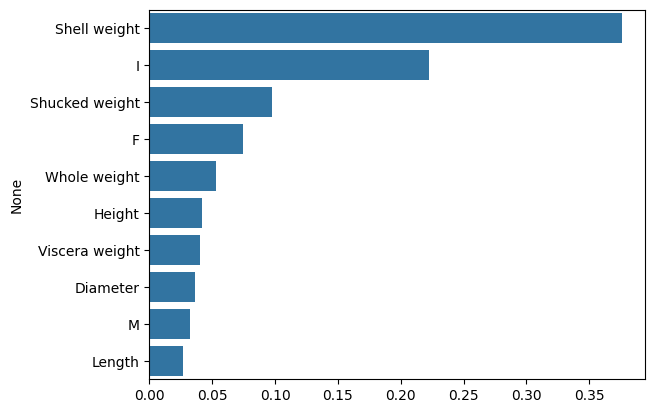

In [18]:
import seaborn as sns
%matplotlib inline
ftr_importances = pd.Series(xgb.feature_importances_, index=data.columns).sort_values(ascending=False)
sns.barplot(x=ftr_importances.values, y=ftr_importances.index)


---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [19]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [20]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [21]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [22]:
lr = LogisticRegression(max_iter=5000)
lr.fit(x_train, y_train)

LogisticRegression(max_iter=5000)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [23]:
#기울기
lr.coef_

array([[ 5.40119857e-01,  5.55141609e-01,  6.20476859e-01,
        -2.58233732e-01, -1.45090139e-04,  2.55690914e-01,
         7.52039277e-01,  8.78394493e-02,  1.63790241e-01,
         1.96653394e-01,  1.22113689e-02,  5.19222294e-01,
         8.77112451e-03],
       [-6.96442843e-01, -9.22500438e-01, -7.03121269e-01,
         1.51118933e-01, -4.31236620e-02,  3.12399569e-01,
         1.59485268e-01,  1.17931800e-02,  3.72214630e-01,
        -9.37234424e-01,  2.86879368e-01,  1.35291197e-01,
        -7.77953721e-03],
       [ 1.56322986e-01,  3.67358828e-01,  8.26444092e-02,
         1.07114799e-01,  4.32687521e-02, -5.68090483e-01,
        -9.11524545e-01, -9.96326293e-02, -5.36004871e-01,
         7.40581030e-01, -2.99090737e-01, -6.54513491e-01,
        -9.91587312e-04]])

In [24]:
#절편
lr.intercept_

array([-15.57767711,  22.74821606,  -7.17053895])

3-3) 모델의 정확도를 구하세요.

In [25]:
#모델의 예측값 구하기
y_pred = lr.predict(x_test)

#모델의 정확도 구하기
print('정확도: {0:.4f}'.format(metrics.accuracy_score(y_test, y_pred)))


정확도: 0.9630
